# Step 1: archive inspection and time-series construction

We checked the 35 monthly folders and built hourly and daily counts for **wp** from the prepared CSVs.
The preparation script processed the whole archive without filtering dates.

Requests were assigned to the dates they happened, rather than their backup dates.
Missing counts were left unknown, and large counts were kept unchanged.

In [46]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_folder = Path.cwd()
if project_folder.name == 'notebooks':
    project_folder = project_folder.parent

outputs_folder = project_folder / 'outputs'
data_folder = project_folder / 'data'


In [47]:
df_hourly = pd.read_csv(outputs_folder / 'tables/hourly.csv')
df_daily = pd.read_csv(outputs_folder / 'tables/daily.csv')
df_audit = pd.read_csv(outputs_folder / 'audit/audit.csv')
df_monthly = pd.read_csv(outputs_folder / 'audit/months.csv', dtype={'month': str})
quality_summary = pd.read_csv(outputs_folder / 'audit/quality_summary.csv')


## Question 1: which files and dates do we have?

`months.csv` is in **`outputs/audit/months.csv`**.
All **35 expected folders, April 2023 to February 2026, are present**.

- `folder_present=False`: the folder is missing, so we do not know its contents.
- `folder_present=True` and `file_count=0`: the folder exists but is empty.

A folder can exist even when some daily log files are missing.

In [48]:
assert len(df_monthly) == 35
assert df_monthly['folder_present'].all()

inventory_columns = ['month', 'folder_present', 'file_count', 'selected_access_files', 'unique_selected_files']
df_monthly[inventory_columns]

,month,folder_present,file_count,selected_access_files,unique_selected_files
0,202304,True,60,38,25
1,202305,True,96,47,31
2,202306,True,109,45,30
3,202307,True,113,46,31
4,202308,True,117,47,31
5,202309,True,109,45,30
6,202310,True,115,46,31
7,202311,True,123,45,30
8,202312,True,141,47,31
9,202401,True,139,46,31


### Log files included in the analysis

| Filename | What it records | Included in wp counts? |
| --- | --- | --- |
| `access.wp.log` or `access.wp.log.1` | Requests to the public WordPress website | Yes |
| `access.doktor.log.1` | Requests to the academic paper search website | No; separate series |
| `error.<service>.log.1` | Server error messages | No |
| `access.nisl-1-stream.log.1` | TCP connections, rather than website requests | No |

A request with status 400, 404 or 500 still belongs in the request count.
It is a request that failed, not an entry from a server error-log file.
The preparation script reads only wp and doktor HTTP access logs.
[Dataset format documentation](https://github.com/cdsl-research/website-access-logs-public#log-format).

In [49]:
print('HTTP example:', next(data_folder.rglob('access.wp.log.1')).name)
print('Error-log example:', next(data_folder.rglob('error.*.log.1')).name)
print('TCP example:', next(data_folder.rglob('access.nisl-1-stream.log.1')).name)


HTTP example: access.wp.log.1
Error-log example: error.clematis.tak-cslab.org.log.1
TCP example: access.nisl-1-stream.log.1


### Backup dates compared with request dates

We examined three wp files, including a backup taken on the first day of a month.
The table shows each backup-folder name, the timestamp on the file's first line,
and the earliest and latest request times listed in the audit.

The first line is not always the earliest request, because log lines may be out of order.

In [50]:
wp_files = df_audit[df_audit['service'] == 'wp'].copy()
month_boundary = wp_files['backup_label'] == 'log-backup-20230501000001'
sample_files = pd.concat([wp_files.head(1), wp_files[month_boundary], wp_files.tail(1)])

In [51]:
sample_dates = []
for file in sample_files.itertuples():
    with (data_folder / file.file).open(encoding='utf-8') as source:
        first_line = source.readline()
    timestamp = first_line.split('[', 1)[1].split(']', 1)[0]
    sample_dates.append([file.backup_label, timestamp, file.first_event_local, file.last_event_local])

sample_columns = ['Backup folder', 'First record timestamp', 'First event (JST)', 'Last event (JST)']
pd.DataFrame(sample_dates, columns=sample_columns)


,Backup folder,First record timestamp,First event (JST),Last event (JST)
0,log-backup-20230403072346,02/Apr/2023:00:00:44 +0900,2023-04-02T00:00:44+09:00,2023-04-02T23:58:10+09:00
1,log-backup-20230501000001,30/Apr/2023:00:01:57 +0900,2023-04-30T00:01:57+09:00,2023-04-30T23:59:47+09:00
2,log-backup-20260204000002,03/Feb/2026:00:00:14 +0900,2026-02-03T00:00:14+09:00,2026-02-03T23:59:41+09:00


The backup taken on **1 May 2023** contained requests from **30 April**.
Those requests were counted in April, even though the file was in the May folder.
The last example was similar: the 4 February 2026 backup contained 3 February requests.

The earliest wp request was **2 April 2023 at 00:00:44 JST**.
The latest was **3 February 2026 at 23:59:41 JST**.

The script read the timezone offset in each request timestamp and grouped requests using
**Japan Standard Time (JST, UTC+09:00)**. `months.csv` was used to describe the backup folders,
not to calculate monthly traffic. Monthly traffic is calculated separately from event dates in Step 2.

## Question 2: what did we find when checking all the files?

`outputs/audit/audit.csv` has one row per file.
For wp and doktor together, the script checked **1,576 files**.
It read the requests in **1,244 different files** and skipped **332 identical copies**.
It identifies copies by comparing file hashes, so it does not need to parse them again.

The tables below show which files were skipped, how many requests were counted,
any lines the script could not read, and the first and last request dates.
The summary also shows hours with no recorded requests.

The local log files were converted to Windows line endings (CRLF). Their byte sizes and SHA-256 hashes therefore differ from the original LF files, but the request counts are unchanged. The audit describes these local copies.


In [52]:
audit_columns = ['file', 'duplicate_of', 'records_used', 'parse_errors', 'first_event_local', 'last_event_local']
df_audit[audit_columns]

,file,duplicate_of,records_used,parse_errors,first_event_local,last_event_local
0,202304/log-backup-20230403072346/access.doktor...,NaN,66,0,2023-03-29T01:13:53+09:00,2023-03-29T16:27:38+09:00
1,202304/log-backup-20230403072346/access.wp.log.1,NaN,7071,0,2023-04-02T00:00:44+09:00,2023-04-02T23:58:10+09:00
2,202304/log-backup-20230403072528/access.doktor...,202304/log-backup-20230403072346/access.doktor...,0,0,2023-03-29T01:13:53+09:00,2023-03-29T16:27:38+09:00
3,202304/log-backup-20230403072528/access.wp.log.1,202304/log-backup-20230403072346/access.wp.log.1,0,0,2023-04-02T00:00:44+09:00,2023-04-02T23:58:10+09:00
4,202304/log-backup-20230404000001/access.wp.log.1,NaN,10837,0,2023-04-03T00:00:30+09:00,2023-04-03T23:59:53+09:00
...,...,...,...,...,...,...
1571,202602/log-backup-20260202000002/access.wp.log.1,NaN,5388,0,2026-02-01T00:00:06+09:00,2026-02-01T23:59:57+09:00
1572,202602/log-backup-20260203000001/access.doktor...,NaN,4381,0,2026-02-02T00:00:25+09:00,2026-02-02T23:59:31+09:00
1573,202602/log-backup-20260203000001/access.wp.log.1,NaN,5741,0,2026-02-02T00:00:22+09:00,2026-02-02T23:59:39+09:00
1574,202602/log-backup-20260204000002/access.doktor...,NaN,3184,0,2026-02-03T00:04:06+09:00,2026-02-03T23:59:07+09:00


In [53]:
summary_columns = ['service', 'unique_files', 'duplicate_files', 'records_used', 'parse_errors', 'unknown_hours', 'complete_days']
quality_summary[summary_columns]

,service,unique_files,duplicate_files,records_used,parse_errors,unknown_hours,complete_days
0,doktor,292,331,507309,0,18017,291
1,wp,952,1,4779893,0,2087,952


### Repeated old files and missing days

- **wp:** 952 different files and one skipped copy; **4,779,893 requests counted**.
- **doktor:** 331 files are copies of the same 66-request log from **29 March 2023**.
  The next different log starts on **8 March 2025**. Copying an old file does not give us new traffic records.
- Both services have **no traffic records from 23 July to 27 August 2025**: 36 days.
- wp also has **no traffic records from 7 December 2024 to 8 January 2025**: 33 days.
- Both services have **no traffic records from 19 to 21 December 2025**: 3 days, or 72 hours.

There is a backup dated 23 July, but its wp file contains only 22 July requests.
It does not provide records for 23 July.

**We do not know why those days have no records.** Files may be missing, logging may have stopped,
or the website may have been unavailable. We left the counts as missing (`NaN`)
rather than assuming there were zero requests.

The **19–21 December gap falls in the intended test period**. There are no observed counts
against which to score forecasts for those dates. The dates remain in the calendar with missing counts;
they cannot contribute to accuracy scores. The number of observed and excluded test dates will be
needed alongside those scores. No test evaluation has been performed yet.

In [54]:
gaps = pd.read_csv(outputs_folder / 'audit/missing_intervals.csv')
wp_gaps = gaps[gaps['service'] == 'wp']
wp_gaps.sort_values('hours', ascending=False)


,service,start_local,end_local_exclusive,hours,location
17,wp,2025-07-23T00:00:00+09:00,2025-08-28T00:00:00+09:00,864,internal
14,wp,2024-12-07T00:00:00+09:00,2025-01-09T00:00:00+09:00,792,internal
7,wp,2023-04-07T00:00:00+09:00,2023-04-11T00:00:00+09:00,96,internal
18,wp,2025-12-19T00:00:00+09:00,2025-12-22T00:00:00+09:00,72,internal
13,wp,2024-11-01T00:00:00+09:00,2024-11-04T00:00:00+09:00,72,internal
10,wp,2024-09-21T01:00:00+09:00,2024-09-23T00:00:00+09:00,47,internal
9,wp,2024-09-19T00:00:00+09:00,2024-09-20T00:00:00+09:00,24,internal
8,wp,2024-08-19T00:00:00+09:00,2024-08-20T00:00:00+09:00,24,internal
11,wp,2024-10-01T00:00:00+09:00,2024-10-02T00:00:00+09:00,24,internal
12,wp,2024-10-07T00:00:00+09:00,2024-10-08T00:00:00+09:00,24,internal


## Question 3: what do we skip, keep or reject?

**A copied file:** two files contain exactly the same bytes. The script uses a SHA-256 hash
to identify these copies within each service. It counts the file once. For later copies,
`duplicate_of` names the original and `records_used=0` means no requests were counted again.

**Repeated lines in one file:** the script keeps them. A client can send the same request
more than once in the same second, producing identical log lines. Deleting them could remove real requests.

The first wp file has **two repeated full lines beyond their first occurrences**.
The check below counts repeated lines in that one file, not across the whole archive.

In [55]:
first_wp_file = data_folder / wp_files.iloc[0]['file']
sample_lines = first_wp_file.read_text(encoding='utf-8').splitlines()
repeated_lines = pd.Series(sample_lines).duplicated().sum()

print('Extra repeated full lines in the first wp file:', repeated_lines)


Extra repeated full lines in the first wp file: 2


### Were any records rejected?

The script rejects a line if it cannot decode its text as UTF-8, recognise the expected log format,
or read a valid timestamp. It counts blank lines separately.
Rejected lines go into `outputs/audit/parse_errors.csv`, with the source file, line number and reason.

**This run had zero rejected records.** There are no rejected examples to inspect.
When there are no failures, the script removes `parse_errors.csv`.

In [56]:
unique_files = df_audit[df_audit['duplicate_of'].isna()]
print('Rejected records:', unique_files['parse_errors'].sum())

errors_file = outputs_folder / 'audit/parse_errors.csv'
if errors_file.exists():
    display(pd.read_csv(errors_file).head())
else:
    print('No parse_errors.csv: no parsing failures were recorded.')


Rejected records: 0
No parse_errors.csv: no parsing failures were recorded.


### Unusual or failed requests can still count

The script counts a line if it can read the log fields and timestamp,
even when the request failed or looks unusual.
That includes monitoring checks, bots, scanners, and requests with 4xx or 5xx responses.
A byte-size field of `-` means the response size is unknown; the request still counts.

Examples found in the first wp file:

| Request field | Status | What the script does |
| --- | --- | --- |
| `GET / HTTP/1.0 ` (extra space at the end) | 400 | Counts it and flags the request format |
| `GET /remote/fgt_lang` (no HTTP version) | 404 | Counts it and flags the request format |
| Empty request field | 400 | Counts it and flags the request format |

`nonstandard_requests` counts requests that do not match the script's expected request pattern.
The flag alone does not mean the record should be deleted.
Also, requests outside the monitoring category can still come from bots rather than people.

In [57]:
wp_hourly_rows = df_hourly[df_hourly['service'] == 'wp']
unusual_columns = ['nonstandard_requests', 'status_4xx', 'status_5xx', 'missing_byte_values']
wp_hourly_rows[unusual_columns].sum().astype(int)


nonstandard_requests       248
status_4xx              196692
status_5xx                 109
missing_byte_values          0
dtype: int64

## Question 4: hourly and daily counts

The wp series now starts on **2 April 2023**, the date of its first recorded request.
The former export started on **29 March** because it used one shared grid for wp and doktor.
A stale doktor file contained requests from 29 March, which extended the shared grid backwards.
Those four days were therefore an artefact of the shared grid, not evidence of missing wp traffic.

We changed the preparation script so each service starts on its own first recorded day,
unless an earlier start date is explicitly requested.
For wp, this removed **96 artificial unknown hours** and **4 artificial missing days**.
The revised counts are **2,087 unknown hours** instead of 2,183, and **87 incomplete or empty days**
instead of 91. No requests were removed; the total remains **4,779,893**.

We converted the request times to JST, sorted them and created an hourly time index.

In [58]:
service = 'wp'
traffic_columns = ['requests', 'monitor_requests', 'other_requests']

hourly = df_hourly[df_hourly['service'] == service].copy()
hourly['time'] = pd.to_datetime(hourly['time_utc'], utc=True)
hourly['time'] = hourly['time'].dt.tz_convert('Asia/Tokyo')
hourly = hourly.set_index('time').sort_index()
assert hourly.index.is_unique, 'Duplicate hourly timestamps'


In [59]:
hourly_counts = hourly[traffic_columns].asfreq('h')
observation_mask = hourly['has_events'].asfreq('h').copy()
raw_hourly_counts = hourly_counts.copy()

hourly_counts.head()


,requests,monitor_requests,other_requests
time,,,
2023-04-02 00:00:00+09:00,233.0,24.0,209.0
2023-04-02 01:00:00+09:00,159.0,24.0,135.0
2023-04-02 02:00:00+09:00,118.0,24.0,94.0
2023-04-02 03:00:00+09:00,162.0,24.0,138.0
2023-04-02 04:00:00+09:00,214.0,24.0,190.0


### Hourly totals compared with retained requests

The hourly counts summed to **4,779,893 wp requests**, matching the total `records_used`
in the file audit.

The comparison used `records_used` because `parsed_records` also includes counts copied
into the audit rows for skipped files. Those copies contributed no additional requests.

In [60]:
retained_records = df_audit.loc[df_audit['service'] == service, 'records_used'].sum()
hourly_total = hourly_counts['requests'].sum()
assert hourly_total == retained_records

print('Retained records:', retained_records)
print('Hourly sum:', int(hourly_total))


Retained records: 4779893
Hourly sum: 4779893


### Missing counts and known zeros

An hour with no request records was left **missing (`NaN`)** because its traffic count was unknown.
A known zero would require evidence that logging worked throughout the hour and no requests occurred.
The access logs did not provide that evidence.

We calculated a daily total only when **all 24 JST hours had recorded requests**.
The `min_count=24` setting left the daily total missing whenever an hour was unknown.
Having records in all 24 hours still did not prove that every request within those hours was logged.

In [61]:
daily_counts = hourly_counts.resample('D').sum(min_count=24)
raw_daily_counts = daily_counts.copy()
daily_counts.head()


,requests,monitor_requests,other_requests
time,,,
2023-04-02 00:00:00+09:00,7071.0,576.0,6495.0
2023-04-03 00:00:00+09:00,10837.0,576.0,10261.0
2023-04-04 00:00:00+09:00,8202.0,576.0,7626.0
2023-04-05 00:00:00+09:00,2645.0,574.0,2071.0
2023-04-06 00:00:00+09:00,3519.0,578.0,2941.0


`requests_recorded` adds up the requests we actually found, even on a day with missing hours.
For example, if only 20 hours have records, it sums those 20 hours, while `requests` stays missing.

On a day with no records, `requests_recorded` is 0. That means **zero records found**,
not proof that the website received zero requests.

In [62]:
service_daily = df_daily[df_daily['service'] == service]
coverage_columns = ['date_local', 'requests', 'requests_recorded', 'hours_with_events', 'unknown_hours']
service_daily[coverage_columns].head(8)

,date_local,requests,requests_recorded,hours_with_events,unknown_hours
0,2023-04-02,7071.0,7071,24,0
1,2023-04-03,10837.0,10837,24,0
2,2023-04-04,8202.0,8202,24,0
3,2023-04-05,2645.0,2645,24,0
4,2023-04-06,3519.0,3519,24,0
5,2023-04-07,NaN,0,0,24
6,2023-04-08,NaN,0,0,24
7,2023-04-09,NaN,0,0,24


In [63]:
coverage = pd.DataFrame({
    'Total periods': [len(hourly_counts), len(daily_counts)],
    'Missing periods': [hourly_counts['requests'].isna().sum(), daily_counts['requests'].isna().sum()],
}, index=['Hours', 'Days'])
coverage

,Total periods,Missing periods
Hours,24936,2087
Days,1039,87


## Question 5: treatment of missing values and large counts

Missing counts were left as `NaN`. Large counts were kept unchanged.
We did not fill gaps, cap spikes, remove large observations or smooth the series.
A spike could reflect real traffic, monitoring checks or scanning; no cause was assumed.

The notebook preserved:

- `raw_hourly_counts` and `raw_daily_counts`: the counts before any corrections.
- `observation_mask`: whether each hour had records. `False` means unknown, not zero requests.
- The unchanged source CSVs, including daily coverage fields and `requests_recorded`.

The chronological split is defined in Step 2. The December gap falls in the test period; no test evaluation has been performed.
No cleaning thresholds or transformations have been fitted. The missing-value treatment for forecasting models will be decided during the experimental design stage, using only past observations.
The original counts and observation mask remain available for comparison with any later corrections.

## Output files and fields

| Output or field | What it tells us |
| --- | --- |
| `outputs/audit/months.csv` | Which of the 35 monthly folders exist and what they contain |
| `outputs/audit/audit.csv` | Requests per file, copied files, and first and last request times |
| `outputs/tables/hourly.csv` | One row per hour, with request counts, monitoring counts, response groups and coverage flags |
| `outputs/tables/daily.csv`: `requests` | Daily total; left missing if any hour is unknown |
| `requests_recorded` | Requests actually found, including on days with missing hours |
| `outputs/audit/parse_errors.csv` | Lines the script could not read, with their file and line number; created only if needed |

## Traffic plots

The daily plot shows the whole period. The hourly plot shows the last 14 calendar days,
ending on the last day with records. Blank sections mean missing counts.
The full series are still available in `hourly_counts` and `daily_counts`.

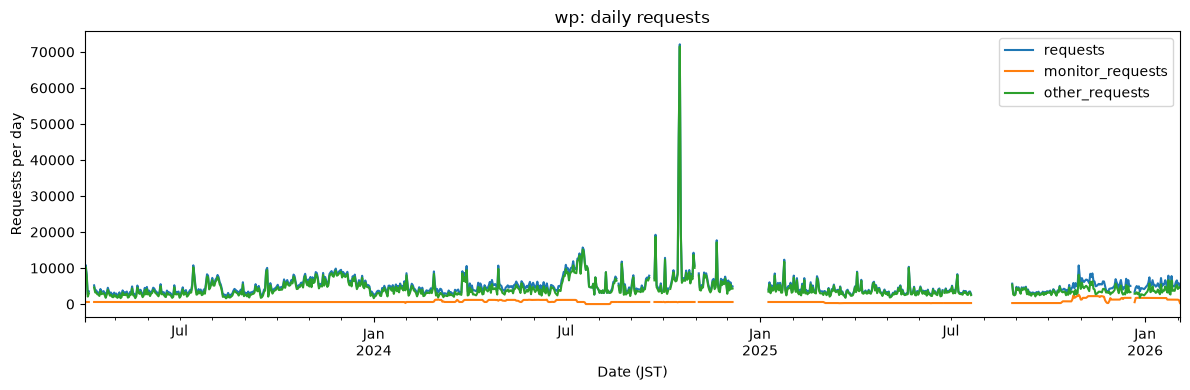

In [64]:
ax = daily_counts.plot(figsize=(12, 4))
ax.set_title(f'{service}: daily requests')
ax.set_xlabel('Date (JST)')
ax.set_ylabel('Requests per day')
plt.tight_layout()
plt.show()


In [65]:
last_hour = hourly_counts['requests'].last_valid_index()
assert last_hour is not None, 'No recorded requests to plot'

last_day = last_hour.normalize()
first_day = last_day - pd.Timedelta(days=13)
end_of_window = last_day + pd.Timedelta(days=1)

recent_hourly = hourly_counts[hourly_counts.index >= first_day]
recent_hourly = recent_hourly[recent_hourly.index < end_of_window]


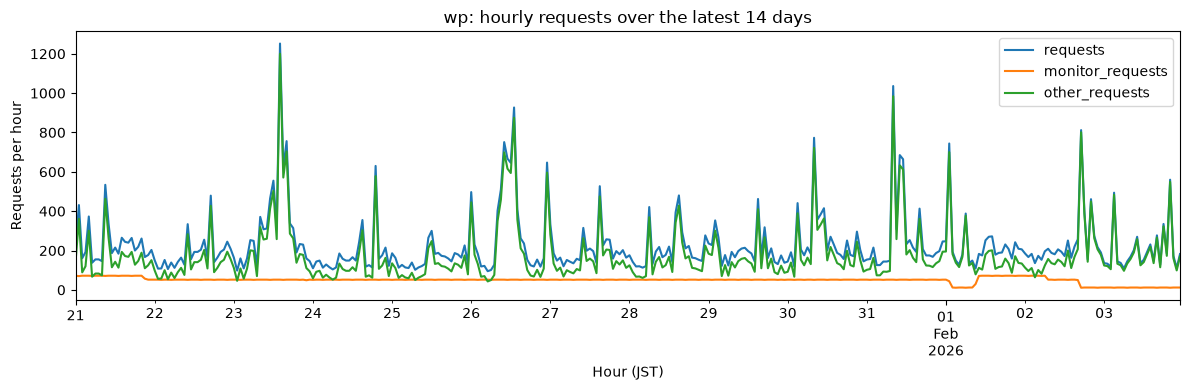

In [66]:
ax = recent_hourly.plot(figsize=(12, 4))
ax.set_title(f'{service}: hourly requests over the latest 14 days')
ax.set_xlabel('Hour (JST)')
ax.set_ylabel('Requests per hour')
plt.tight_layout()
plt.show()


# Step 2: Exploratory data analysis

We study the WordPress traffic over the full event-date range.
The goal is to understand changes in traffic, variability,
seasonal patterns and unusual activity before forecasting.

Missing observations and large counts are kept unchanged.

In [67]:
daily_wp = daily_counts.copy()
hourly_wp = hourly.copy()

daily_wp.head()

,requests,monitor_requests,other_requests
time,,,
2023-04-02 00:00:00+09:00,7071.0,576.0,6495.0
2023-04-03 00:00:00+09:00,10837.0,576.0,10261.0
2023-04-04 00:00:00+09:00,8202.0,576.0,7626.0
2023-04-05 00:00:00+09:00,2645.0,574.0,2071.0
2023-04-06 00:00:00+09:00,3519.0,578.0,2941.0


In [68]:
train = daily_wp.loc[:"2025-10-12"]
validation = daily_wp.loc["2025-10-13":"2025-12-07"]
test = daily_wp.loc["2025-12-08":"2026-02-01"]

for name, data in [("Train", train), ("Validation", validation), ("Test", test)]:
    print(name)
    print("Total days:", len(data))
    print("Observed days:", data["requests"].count())
    print("Missing days:", data["requests"].isna().sum())
    print()

Train
Total days: 925
Observed days: 841
Missing days: 84

Validation
Total days: 56
Observed days: 56
Missing days: 0

Test
Total days: 56
Observed days: 53
Missing days: 3



The last 16 complete Monday-to-Sunday weeks form the validation and test periods. The final two days (February 2–3, 2026) remain in the historical analysis only. The three unknown test days are December 19–21, 2025.

## Question 6: Daily traffic and monthly summaries

We first look at the entire history to identify changes
in traffic levels, unusual peaks and missing periods.

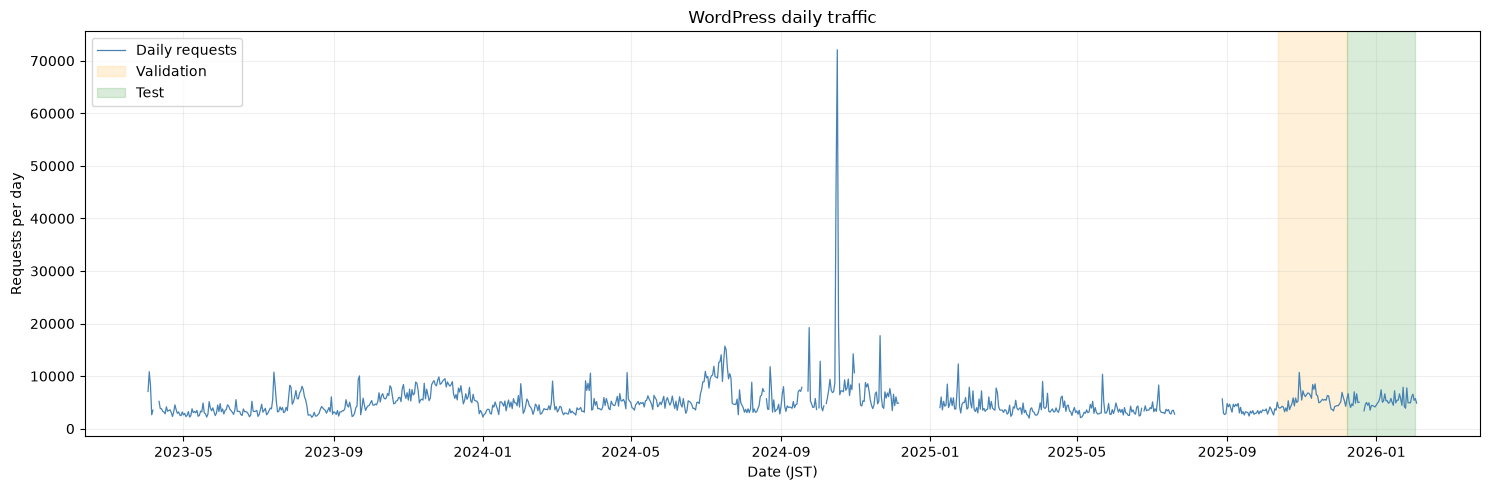

In [69]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_wp.index, daily_wp["requests"], color="steelblue", linewidth=0.9, label="Daily requests")
ax.axvspan(validation.index.min(), test.index.min(), color="orange", alpha=0.15, label="Validation")
ax.axvspan(test.index.min(), test.index.max() + pd.Timedelta(days=1), color="green", alpha=0.15, label="Test")

ax.set_title("WordPress daily traffic")
ax.set_xlabel("Date (JST)")
ax.set_ylabel("Requests per day")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [70]:
monthly = daily_wp["requests"].resample("MS").agg(["sum", "mean", "median", "std", "count"])
monthly = monthly.rename(columns={"sum": "total_requests", "mean": "mean_daily_requests", "median": "median_daily_requests",
                                  "std": "std_daily_requests", "count": "observed_days"})

monthly["days_in_month"] = monthly.index.days_in_month
monthly["missing_days"] = daily_wp["requests"].resample("MS").size() - monthly["observed_days"]

# The first and last months may not be fully covered by the archive.
monthly["coverage_pct"] = monthly["observed_days"] / monthly["days_in_month"] * 100

# A month without observations has an unknown total, not zero.
monthly.loc[monthly["observed_days"] == 0, "total_requests"] = float("nan")
monthly.round(2)

,total_requests,mean_daily_requests,median_daily_requests,std_daily_requests,observed_days,days_in_month,missing_days,coverage_pct
time,,,,,,,,
2023-04-01 00:00:00+09:00,100032.0,4001.28,3314.0,1962.75,25,30,4,83.33
2023-05-01 00:00:00+09:00,99692.0,3215.87,3059.0,788.71,31,31,0,100.00
2023-06-01 00:00:00+09:00,102333.0,3411.10,3302.0,721.40,30,30,0,100.00
2023-07-01 00:00:00+09:00,139838.0,4510.90,3874.0,1942.29,31,31,0,100.00
2023-08-01 00:00:00+09:00,131359.0,4237.39,3680.0,1791.15,31,31,0,100.00
2023-09-01 00:00:00+09:00,123355.0,4111.83,3823.5,1757.84,30,30,0,100.00
2023-10-01 00:00:00+09:00,183160.0,5908.39,5858.0,1085.63,31,31,0,100.00
2023-11-01 00:00:00+09:00,221769.0,7392.30,7514.5,1536.35,30,30,0,100.00
2023-12-01 00:00:00+09:00,197125.0,6358.87,6395.0,1739.80,31,31,0,100.00


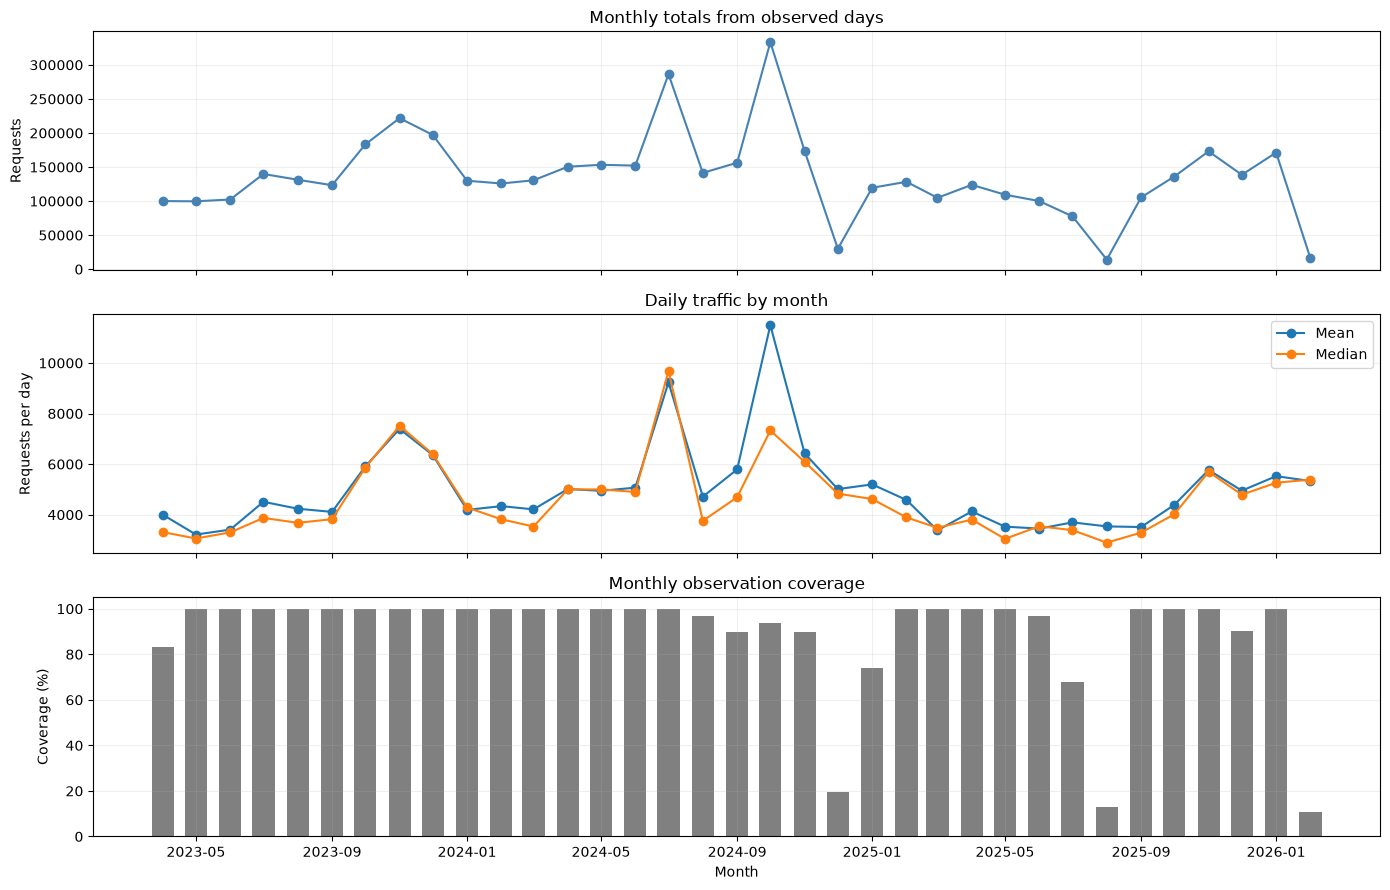

In [71]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

axes[0].plot(monthly.index, monthly["total_requests"], marker="o", color="steelblue")
axes[0].set_ylabel("Requests")
axes[0].set_title("Monthly totals from observed days")

axes[1].plot(monthly.index, monthly["mean_daily_requests"], marker="o", label="Mean")
axes[1].plot(monthly.index, monthly["median_daily_requests"], marker="o", label="Median")
axes[1].set_ylabel("Requests per day")
axes[1].set_title("Daily traffic by month")
axes[1].legend()

axes[2].bar(monthly.index, monthly["coverage_pct"], width=20, color="gray")
axes[2].set_ylabel("Coverage (%)")
axes[2].set_ylim(0, 105)
axes[2].set_title("Monthly observation coverage")
axes[2].set_xlabel("Month")

for ax in axes:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Monthly totals depend on both traffic levels and data coverage.
August 2025 has only 4 observed days, compared with 30 in September. Their totals differ (14,154 and 105,385), but their mean daily counts are close (3,539 and 3,513).
December 2024 also has low coverage, with only 6 observed days.

The first and last months are only partly inside the archive. `missing_days` counts unknown days within the archive, whereas `coverage_pct` uses the full calendar month.
We compare daily means and medians alongside coverage instead of relying on monthly totals alone. Missing days may still bias these statistics.

## Question 7: Trend, variability and seasonality

We describe the full history and use the training period to study patterns that may guide model choices. The later periods are shown for description only.

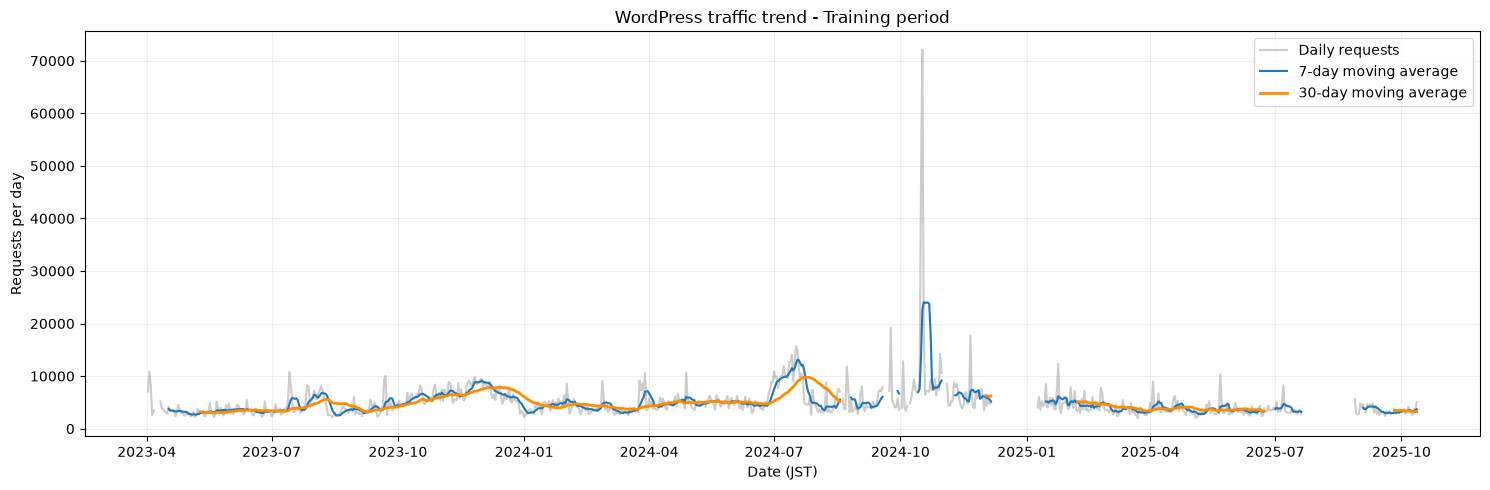

In [72]:
# A weekly and a monthly rolling average help show the trend.
rolling_7 = train["requests"].rolling(window=7, min_periods=7).mean()
rolling_30 = train["requests"].rolling(window=30, min_periods=30).mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(train.index, train["requests"], color="gray", alpha=0.4, label="Daily requests")
ax.plot(rolling_7, label="7-day moving average")
ax.plot(rolling_30, color="darkorange", linewidth=2, label="30-day moving average")

ax.set_title("WordPress traffic trend - Training period")
ax.set_xlabel("Date (JST)")
ax.set_ylabel("Requests per day")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [73]:
yearly_stats = train["requests"].groupby(train.index.year).agg(["count", "mean", "median", "std", "min", "max"])
yearly_stats["cv"] = yearly_stats["std"] / yearly_stats["mean"]
yearly_stats.round(2)

,count,mean,median,std,min,max,cv
time,,,,,,,
2023,270,4809.86,4192.0,2034.16,2158.0,10837.0,0.42
2024,332,5912.38,4800.0,5051.49,2204.0,72098.0,0.85
2025,239,3874.52,3556.0,1347.73,2017.0,12313.0,0.35


Traffic levels are not constant across the training period. In the observed part of 2024, the daily mean is 5,912 requests and the coefficient of variation is 0.85, compared with 0.42 in 2023 and 0.35 in 2025.
The large October 2024 peaks partly explain this difference. The 2025 training observations have a lower mean (3,875) and less variability.

The years have different observation periods and missing days, so these are not comparisons of three complete calendar years.

In [74]:
# Include the rest of the archive for descriptive comparisons only.
partial_week = daily_wp.loc["2026-02-02":]
periods = {"Train": train, "Validation": validation, "Test": test, "Final partial week": partial_week}
period_stats = pd.DataFrame({name: data["requests"].describe() for name, data in periods.items()}).T
period_stats["calendar_days"] = [len(data) for data in periods.values()]
period_stats["missing_days"] = period_stats["calendar_days"] - period_stats["count"]
period_stats.round(2)

,count,mean,std,min,25%,50%,75%,max,calendar_days,missing_days
Train,841.0,4979.29,3549.01,2017.0,3318.0,4132.0,5655.00,72098.0,925,84.0
Validation,56.0,5412.52,1461.16,3222.0,4256.5,5280.5,6292.75,10715.0,56,0.0
Test,53.0,5256.58,1040.12,3395.0,4464.0,4999.0,5676.00,7877.0,56,3.0
Final partial week,2.0,5304.00,618.01,4867.0,5085.5,5304.0,5522.50,5741.0,2,0.0


The observed mean rises to about 5,413 requests in validation and 5,257 in test, compared with 4,979 in the full training period. Both later periods have a lower standard deviation than the train. The final partial week contains only two observations, so it is not comparable to the longer periods. These results describe the archive; they are not used to select model settings.

In [75]:
weekday_stats = train["requests"].groupby(train.index.day_of_week).agg(["mean", "median", "std", "count"])
weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_stats.index = weekdays
weekday_stats.round(2)

,mean,median,std,count
Monday,5184.25,4884.0,1964.83,118
Tuesday,5116.27,4509.0,2294.45,120
Wednesday,5239.88,4409.0,4359.41,121
Thursday,5610.88,4029.5,6577.29,122
Friday,4985.73,4061.0,2612.78,121
Saturday,4307.94,3623.0,2006.01,119
Sunday,4395.15,3605.5,2118.82,120


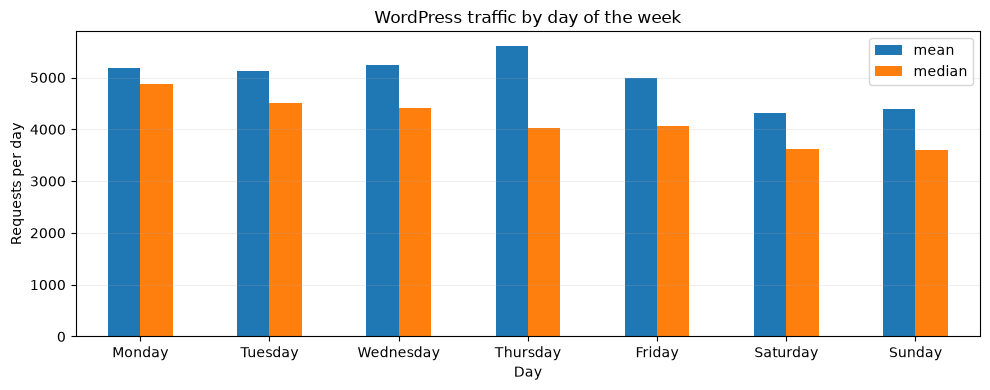

In [76]:
weekday_stats[["mean", "median"]].plot(kind="bar",figsize=(10, 4))

plt.title("WordPress traffic by day of the week")
plt.xlabel("Day")
plt.ylabel("Requests per day")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [77]:
weekday_profile = train["requests"].groupby([train.index.day_of_week, train.index.year]).median().unstack()
weekday_profile.index = weekdays
weekday_profile.round(2)

time,2023,2024,2025
Monday,5108.0,5450.0,4010.0
Tuesday,4514.0,5176.5,3744.0
Wednesday,4309.0,4832.0,3253.0
Thursday,4009.0,4751.0,3520.0
Friday,3866.0,4843.0,3639.0
Saturday,3145.0,4078.0,3330.0
Sunday,3449.0,4122.5,3225.0


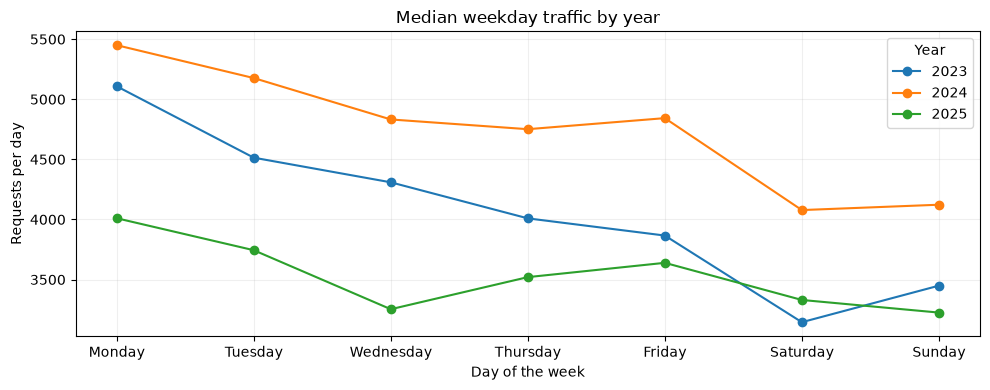

In [78]:
weekday_profile.plot(marker="o", figsize=(10, 4))

plt.title("Median weekday traffic by year")
plt.xlabel("Day of the week")
plt.ylabel("Requests per day")
plt.grid(alpha=0.2)
plt.legend(title="Year")

plt.tight_layout()
plt.show()

Monday has the highest median traffic in each of the three training years. Weekend traffic is generally lower, although the differences between days are smaller in 2025. The high Thursday mean is influenced by the large October 2024 peaks.

In [79]:
# Check whether the weekday profile changes in the later periods.
period_weekdays = pd.DataFrame({name: data["requests"].groupby(data.index.day_of_week).median()
                                for name, data in periods.items() if name != "Final partial week"})
period_weekdays = period_weekdays.reindex(range(7))
period_weekdays.index = weekdays
period_weekdays.round(2)

,Train,Validation,Test
Monday,4884.0,5159.0,5233.0
Tuesday,4509.0,5145.5,5394.0
Wednesday,4409.0,5192.0,4982.5
Thursday,4029.5,6005.5,4461.5
Friday,4061.0,5710.5,5283.0
Saturday,3623.0,5347.0,4900.0
Sunday,3605.5,4714.0,5388.0


The later profiles are less consistent with the training pattern: Thursday has the highest median in validation and Tuesday in test, rather than Monday. The later periods each cover only eight weeks, so this is descriptive evidence of change, not a basis for choosing model parameters.

In [80]:
annual_profile = train["requests"].groupby([train.index.month, train.index.year]).median().unstack()
annual_profile = annual_profile.reindex(range(1, 13))
annual_profile.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
annual_profile.round(2)

time,2023,2024,2025
Jan,NaN,4287.0,4619.0
Feb,NaN,3817.0,3892.5
Mar,NaN,3533.0,3483.0
Apr,3314.0,5001.5,3807.5
May,3059.0,5000.0,3045.0
Jun,3302.0,4901.5,3544.0
Jul,3874.0,9683.0,3389.0
Aug,3680.0,3759.5,2897.5
Sep,3823.5,4690.0,3293.0
Oct,5858.0,7330.0,3491.5


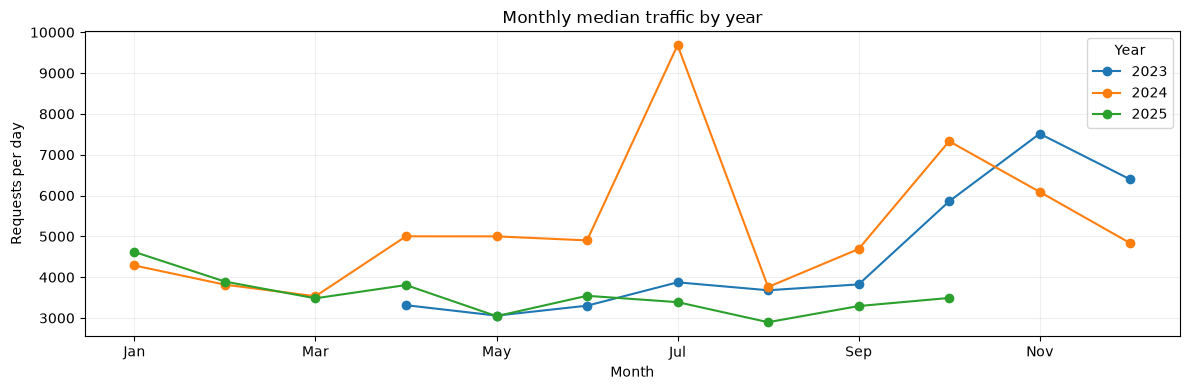

In [81]:
annual_profile.plot(marker="o", figsize=(12, 4))

plt.title("Monthly median traffic by year")
plt.xlabel("Month")
plt.ylabel("Requests per day")
plt.grid(alpha=0.2)
plt.legend(title="Year")

plt.tight_layout()
plt.show()

In [82]:
train["requests"].groupby([train.index.month, train.index.year]).count().unstack()

time,2023,2024,2025
time,,,
1,NaN,31.0,23.0
2,NaN,29.0,28.0
3,NaN,31.0,31.0
4,25.0,30.0,30.0
5,31.0,31.0,31.0
6,30.0,30.0,29.0
7,31.0,31.0,21.0
8,31.0,30.0,4.0
9,30.0,27.0,30.0


July 2024 has a much higher median traffic (9,683) than July 2023 (3,874) or July 2025 (3,389).
The monthly profiles do not show a clear pattern that repeats every year. There are fewer than three annual cycles in the archive and some months have very few observed days.

A weekly seasonal period of 7 is a reasonable candidate for the forecasting experiment, based on the training weekday profiles. We will check it with the training ACF and validation results in Step 3 rather than assume it is the best choice.

## Question 8: Monitoring traffic and unusual activity

Some requests are generated by automated monitoring tools.
We compare total traffic with traffic after removing the
identified monitoring requests.

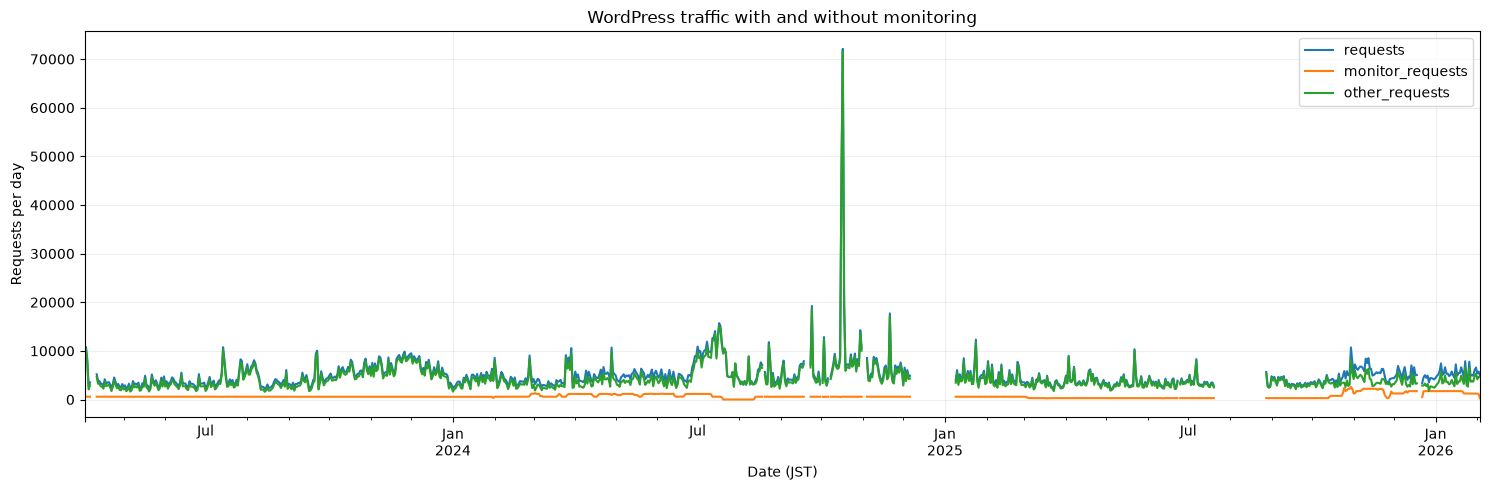

In [83]:
daily_wp[["requests", "monitor_requests", "other_requests"]].plot(figsize=(15, 5))

plt.title("WordPress traffic with and without monitoring")
plt.xlabel("Date (JST)")
plt.ylabel("Requests per day")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [84]:
monitoring_stats = train[["requests", "monitor_requests", "other_requests"]].groupby(train.index.year).sum(min_count=1)
monitoring_stats["monitoring_pct"] = monitoring_stats["monitor_requests"] / monitoring_stats["requests"] * 100
monitoring_stats.round(2)

,requests,monitor_requests,other_requests,monitoring_pct
time,,,,
2023,1298663.0,155270.0,1143393.0,11.96
2024,1962910.0,234098.0,1728812.0,11.93
2025,926010.0,83108.0,842902.0,8.97


In [85]:
monitoring_pct = train["monitor_requests"].sum() / train["requests"].sum() * 100
print(f"Monitoring traffic in the training period: {monitoring_pct:.2f}%")

Monitoring traffic in the training period: 11.28%


Identified monitoring accounts for about 11.28% of the observed training traffic. Its share is close to 12% in 2023 and 2024, and about 9% in the 2025 training observations. Other requests can still include bots and scanners; they are not necessarily human traffic.

We compare October 9–11 with October 16–18, 2024: the same weekdays one week apart, with complete hourly coverage and both inside the training period.

In [86]:
normal = hourly_wp.loc["2024-10-09":"2024-10-11"]
burst = hourly_wp.loc["2024-10-16":"2024-10-18"]

print("Reference period:", len(normal), "hours")
print("High traffic period:", len(burst), "hours")
print("Missing hours in reference period:", normal["requests"].isna().sum())
print("Missing hours in high traffic period:", burst["requests"].isna().sum())

Reference period: 72 hours
High traffic period: 72 hours
Missing hours in reference period: 0
Missing hours in high traffic period: 0


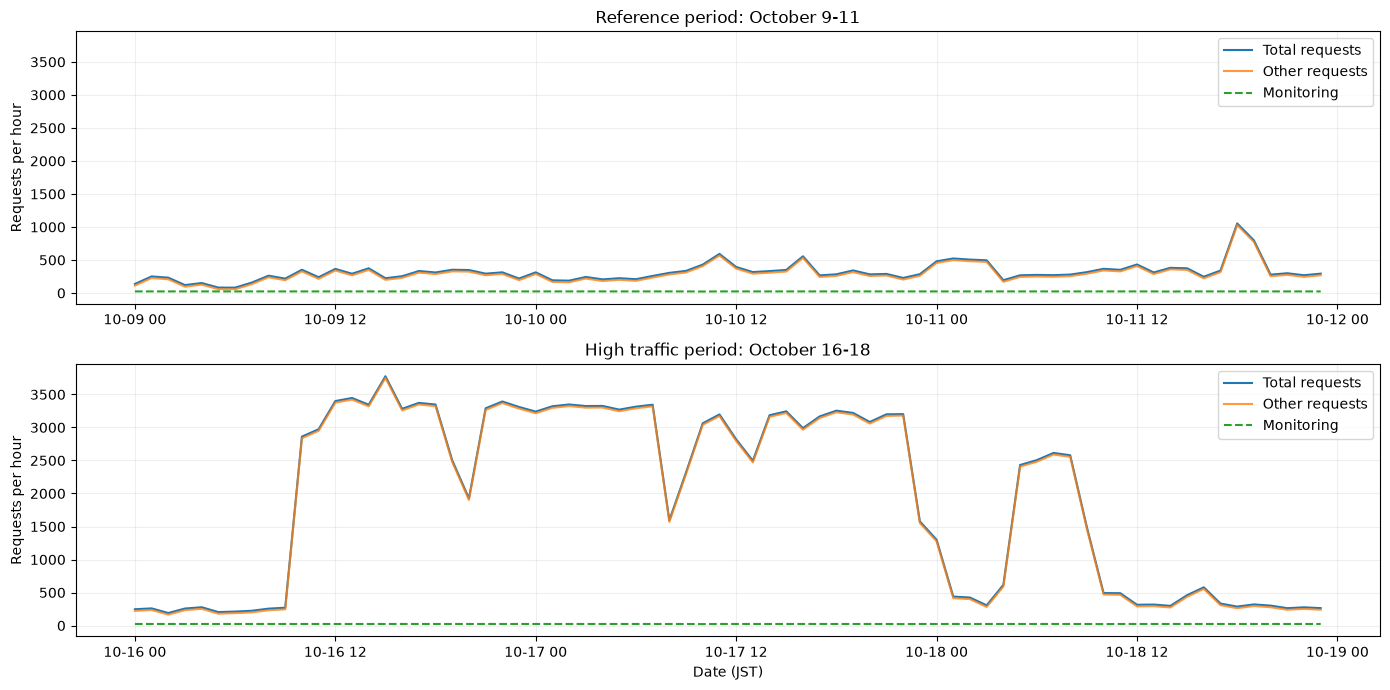

In [87]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharey=True)
episodes = [("Reference period: October 9-11", normal), ("High traffic period: October 16-18", burst)]

for ax, (title, data) in zip(axes, episodes):
    ax.plot(data.index, data["requests"], label="Total requests")
    ax.plot(data.index, data["other_requests"], label="Other requests", alpha=0.8)
    ax.plot(data.index, data["monitor_requests"], label="Monitoring", linestyle="--")
    ax.set_title(title)
    ax.set_ylabel("Requests per hour")
    ax.legend()
    ax.grid(alpha=0.2)

axes[-1].set_xlabel("Date (JST)")
plt.tight_layout()
plt.show()

In [88]:
episode_stats = pd.DataFrame({
    "Reference period": normal["requests"].describe(),
    "High traffic period": burst["requests"].describe()
})

episode_stats.round(2)

,Reference period,High traffic period
count,72.00,72.00
mean,316.31,1922.46
std,145.67,1362.53
min,81.00,190.00
25%,242.00,317.25
50%,292.50,2498.50
75%,351.25,3246.50
max,1053.00,3775.00


In [89]:
peak_hour = burst["requests"].idxmax()

print("Peak hour:", peak_hour)
print("Requests:", burst.loc[peak_hour, "requests"])

Peak hour: 2024-10-16 15:00:00+09:00
Requests: 3775.0


In [90]:
columns = ["requests", "monitor_requests", "other_requests", "declared_bot_requests", "unique_clients",
           "status_2xx", "status_3xx", "status_4xx", "status_5xx"]
burst.loc[peak_hour, columns]

requests                 3775.0
monitor_requests           24.0
other_requests           3751.0
declared_bot_requests    3132.0
unique_clients            119.0
status_2xx               3729.0
status_3xx                 42.0
status_4xx                  4.0
status_5xx                  0.0
Name: 2024-10-16 15:00:00+09:00, dtype: float64

In [91]:
status_columns = ["status_1xx", "status_2xx", "status_3xx", "status_4xx", "status_5xx", "status_other"]
response_counts = pd.DataFrame({"Reference": normal[status_columns].sum(min_count=1),
                                "High traffic": burst[status_columns].sum(min_count=1)}).T
response_pct = response_counts.div(response_counts.sum(axis=1), axis=0) * 100
response_pct.round(2)

,status_1xx,status_2xx,status_3xx,status_4xx,status_5xx,status_other
Reference,0.0,91.33,7.71,0.96,0.01,0.0
High traffic,0.0,97.71,1.69,0.60,0.00,0.0


In [92]:
for name, data in [("Reference", normal), ("High traffic", burst)]:
    total = data["requests"].sum()
    peak = data["requests"].max()
    print(name)
    print("Total requests:", int(total))
    print("Maximum hourly requests:", int(peak))
    print(f"Peak hour share: {peak / total * 100:.2f}%")
    print()

Reference
Total requests: 22774
Maximum hourly requests: 1053
Peak hour share: 4.62%

High traffic
Total requests: 138417
Maximum hourly requests: 3775
Peak hour share: 2.73%



In [93]:
for name, data in [("Reference", normal), ("High traffic", burst)]:
    total = data["requests"].sum()
    bot_pct = data["declared_bot_requests"].sum() / total * 100
    monitor_pct = data["monitor_requests"].sum() / total * 100
    print(name)
    print(f"Declared bots: {bot_pct:.2f}%")
    print(f"Monitoring: {monitor_pct:.2f}%")
    print()

Reference
Declared bots: 29.67%
Monitoring: 7.57%

High traffic
Declared bots: 87.93%
Monitoring: 1.24%



The high traffic episode has about six times more requests than the reference period (138,417 against 22,774). The hourly median rises from 292.5 to 2,498.5. The busiest hour accounts for only 2.73% of the high traffic episode, against 4.62% in the reference period. This shows that the increase was not limited to one isolated hour.

The busiest hour occurred on October 16 at 15:00 JST, with 3,775 requests. About 83% were flagged as declared bot traffic, while only 24 were identified as monitoring requests. Across the two episodes, the bot share rises from about 30% to 88%, while the monitoring share falls from 7.57% to 1.24%. The bot and monitoring categories can overlap, and user-agent labels do not establish the true identity of the client.

The share of successful HTTP responses rises from 91.33% to 97.71%, with no recorded 5xx responses during the high traffic episode. The increase appears to involve substantial automated activity, but the exact cause cannot be established from these fields alone. Daily totals hide both the timing and the duration of this activity.

In [94]:
target = daily_wp["requests"].copy()
target.name = "daily_requests"

## Forecasting target

We use the total number of daily WordPress requests as our
forecasting target.

Monitoring requests are included because they contribute to
the overall website activity.

The same target will be used for all forecasting methods.
Missing observations and large traffic peaks remain unchanged
at this stage.